# 01 Exploratory data analysis

PlantVillage (color subset, 38 classes) is our training data: lab photos of single leaves on a plain background. PlantDoc is a separate set of field photos from the web that we only use for testing. This notebook looks at class balance, image size and color, repeated photos of the same leaf, duplicates and label problems in PlantDoc, and what the images look like after preprocessing.

Run these from the repo root first:

```bash
python -m src.data.download
python -m src.data.splits
```

The figures are also saved to `figures/` (charts as PNG, photo grids as JPEG).

In [1]:
%matplotlib inline

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image as IPImage
from IPython.display import display
from PIL import Image, ImageOps

here = Path.cwd().resolve()
for candidate in [here, *here.parents]:
    if (candidate / "src" / "data" / "labels.py").is_file():
        ROOT = candidate
        break
else:
    raise RuntimeError("Could not find the repository root. Open this notebook from the project directory.")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.labels import (
    NUM_CLASSES,
    PLANTDOC_WITHOUT_USABLE_IMAGES,
    UNMAPPED_PLANTVILLAGE,
    crop_and_condition,
    display_crop,
    is_healthy,
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_colwidth", 100)

PV_COLOR = "#2b8cbe"
PD_COLOR = "#e6550d"
HEALTHY_COLOR = "#2ca25f"
MUTED_COLOR = "#bdbdbd"
RNG = np.random.default_rng(42)
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)


def show(fig, name, photo=False):
    # Save to figures/ and display. Photo grids are saved as JPEG to keep the
    # notebook small.
    if photo:
        path = FIG_DIR / f"{name}.jpg"
        fig.savefig(path, dpi=90, bbox_inches="tight", pil_kwargs={"quality": 82})
        plt.close(fig)
        display(IPImage(filename=str(path)))
    else:
        fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
        display(fig)
        plt.close(fig)


def open_upright(raw, max_side=None):
    # Same as the loader: apply EXIF rotation, convert to RGB.
    with Image.open(ROOT / raw) as image:
        image = ImageOps.exif_transpose(image).convert("RGB")
    if max_side:
        image.thumbnail((max_side, max_side))
    return image


def load_split_tables():
    frames = []
    for name in ("train", "val", "test"):
        path = ROOT / "data" / "splits" / f"{name}.csv"
        if not path.is_file():
            raise FileNotFoundError(f"Missing {path}. Run: python -m src.data.splits")
        frames.append(pd.read_csv(path).assign(split=name))
    plantvillage = pd.concat(frames, ignore_index=True)
    plantdoc_path = ROOT / "data" / "splits" / "plantdoc_test.csv"
    if not plantdoc_path.is_file():
        raise FileNotFoundError(f"Missing {plantdoc_path}. PlantDoc did not download.")
    plantdoc = pd.read_csv(plantdoc_path)
    excluded = pd.read_csv(ROOT / "data" / "plantdoc_excluded.csv", keep_default_na=False)
    for frame, name in ((plantvillage, "PlantVillage"), (plantdoc, "PlantDoc"), (excluded, "excluded PlantDoc")):
        missing = [row for row in frame["path"] if not (ROOT / row).is_file()]
        if missing:
            raise FileNotFoundError(f"{len(missing)} {name} files from the CSVs are not on disk. First missing: {missing[0]}")
    return plantvillage, plantdoc, excluded


def short_label(label: str) -> str:
    crop = display_crop(label)
    _crop, condition = crop_and_condition(label)
    return f"{crop}: {condition.replace('_', ' ').strip()}"


plantvillage, plantdoc, plantdoc_excluded = load_split_tables()
label_map = pd.read_csv(ROOT / "data" / "plantdoc_label_map.csv", keep_default_na=False)
print(f"PlantVillage images: {len(plantvillage):,}")
print(f"PlantVillage classes: {plantvillage['label'].nunique()} (expected {NUM_CLASSES})")
print(plantvillage["split"].value_counts().rename("images").to_string())
print(f"PlantDoc field-test images: {len(plantdoc):,} across {plantdoc['label'].nunique()} classes "
      f"({len(plantdoc_excluded)} more are excluded; see data/plantdoc_excluded.csv)")
no_field = len(UNMAPPED_PLANTVILLAGE) + len(PLANTDOC_WITHOUT_USABLE_IMAGES)
print(f"PlantVillage classes with no PlantDoc photos: {no_field}")

PlantVillage images: 54,305
PlantVillage classes: 38 (expected 38)
split
train    38014
test      8147
val       8144
PlantDoc field-test images: 2,269 across 27 classes (309 more are excluded; see data/plantdoc_excluded.csv)
PlantVillage classes with no PlantDoc photos: 11


## Class counts

A few classes hold a large share of the images, and the smallest class is healthy potato. The splits keep each class at about 70/15/15, so all three have the same skew. Accuracy alone can look good even if the small classes are missed, so we also need macro-F1 and per-class recall.

Largest class: Orange___Haunglongbing_(Citrus_greening) (5,507)
Smallest class: Potato___healthy (152)
Median class size: 1092
Imbalance ratio (largest / smallest): 36.23
Share of images in the 3 largest classes: 29.4%


,label,images,share,crop,healthy,rank
0,Orange___Haunglongbing_(Citrus_greening),5507,10.14,Orange,False,1
1,Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357,9.86,Tomato,False,2
2,Soybean___healthy,5090,9.37,Soybean,True,3
3,Peach___Bacterial_spot,2297,4.23,Peach,False,4
4,Tomato___Bacterial_spot,2127,3.92,Tomato,False,5
5,Tomato___Late_blight,1909,3.52,Tomato,False,6
6,Squash___Powdery_mildew,1835,3.38,Squash,False,7
7,Tomato___Septoria_leaf_spot,1771,3.26,Tomato,False,8
8,Tomato___Spider_mites Two-spotted_spider_mite,1676,3.09,Tomato,False,9
9,Apple___healthy,1645,3.03,Apple,True,10


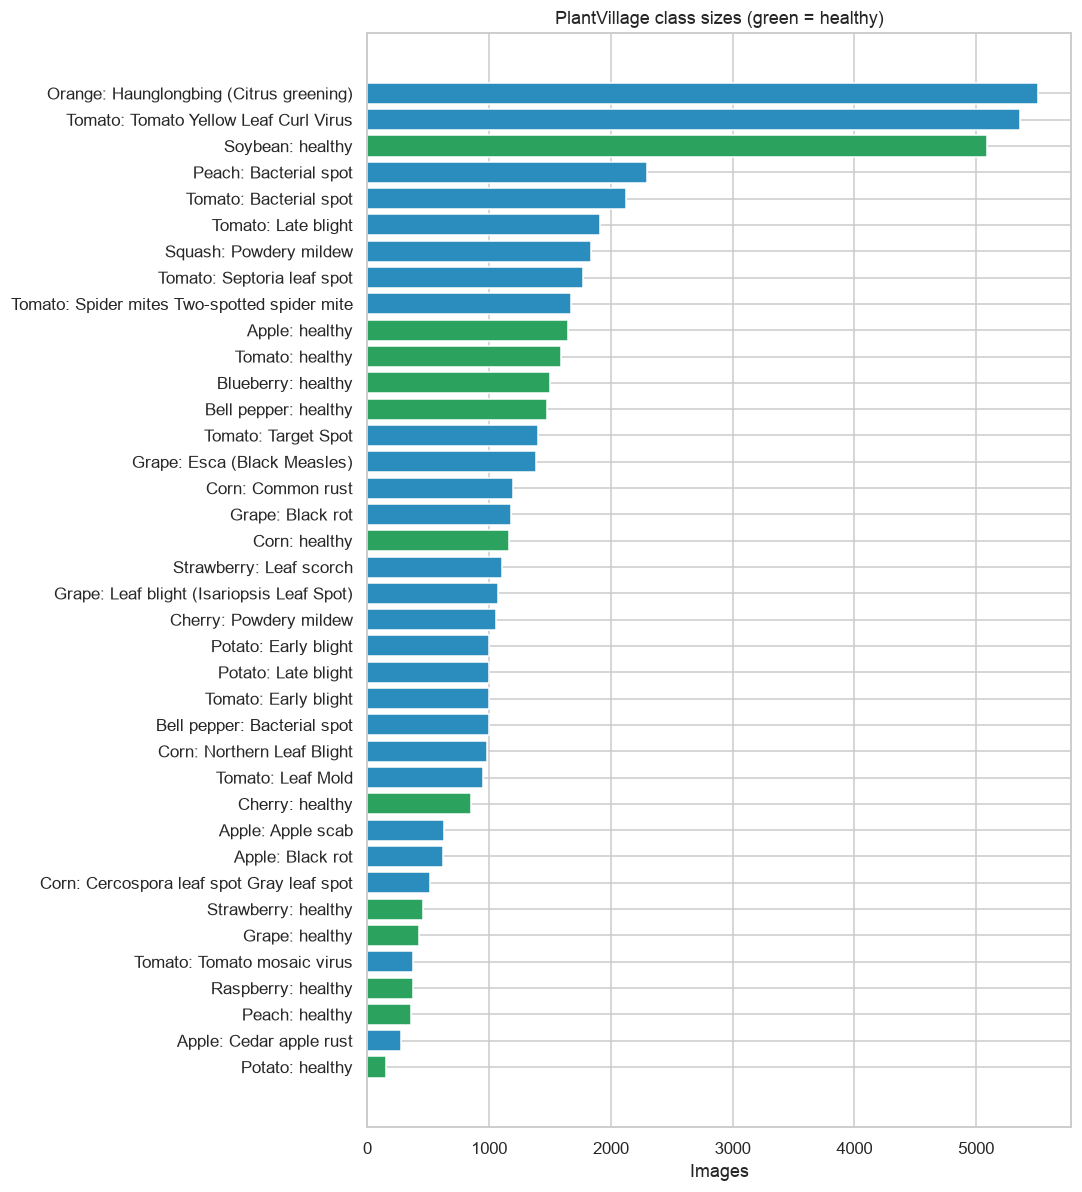

In [2]:
counts = (
    plantvillage.groupby("label")
    .size()
    .rename("images")
    .reset_index()
    .sort_values(["images", "label"], ascending=[False, True], kind="stable")
    .reset_index(drop=True)
)
counts["share"] = counts["images"] / counts["images"].sum()
counts["crop"] = counts["label"].map(display_crop)
counts["healthy"] = counts["label"].map(is_healthy)
counts["rank"] = np.arange(1, len(counts) + 1)

imbalance_ratio = counts["images"].max() / counts["images"].min()
top3_share = counts["images"].head(3).sum() / counts["images"].sum()
print(f"Largest class: {counts.loc[0, 'label']} ({int(counts.loc[0, 'images']):,})")
print(f"Smallest class: {counts.loc[len(counts) - 1, 'label']} ({int(counts.loc[len(counts) - 1, 'images']):,})")
print(f"Median class size: {counts['images'].median():.0f}")
print(f"Imbalance ratio (largest / smallest): {imbalance_ratio:.2f}")
print(f"Share of images in the 3 largest classes: {top3_share:.1%}")
display(counts.assign(share=lambda frame: (frame["share"] * 100).round(2)))

order = counts.iloc[::-1]
bar_colors = [HEALTHY_COLOR if flag else PV_COLOR for flag in order["healthy"]]
fig, ax = plt.subplots(figsize=(10, 11))
ax.barh(order["label"].map(short_label), order["images"], color=bar_colors)
ax.set_xlabel("Images")
ax.set_title("PlantVillage class sizes (green = healthy)")
fig.tight_layout()
show(fig, "plantvillage_class_sizes")

## Splits

Most PlantVillage leaves were photographed several times, so the split is done by leaf (the `group` column) with `StratifiedGroupKFold` (20 folds, seed 42; folds 0-2 test, 3-5 val, 6-19 train). This checks that no image or group is in two splits and that each class is still close to 70/15/15.

In [3]:
paths = {name: set(plantvillage.loc[plantvillage["split"] == name, "path"]) for name in ("train", "val", "test")}
groups = {name: set(plantvillage.loc[plantvillage["split"] == name, "group"]) for name in ("train", "val", "test")}
pairs = (("train", "val"), ("train", "test"), ("val", "test"))
print(f"Images in more than one split: {sum(len(paths[a] & paths[b]) for a, b in pairs)}")
print(f"Leaf/file groups in more than one split: {sum(len(groups[a] & groups[b]) for a, b in pairs)}")
fold_split = plantvillage.groupby("fold")["split"].agg(lambda s: "/".join(sorted(set(s))))
print("Folds per split:", {name: sorted(fold_split[fold_split == name].index.tolist()) for name in ("test", "val", "train")})
fold_sizes = plantvillage["fold"].value_counts()
print(f"Fold sizes: {fold_sizes.min():,} to {fold_sizes.max():,} images")
wide = plantvillage.groupby(["label", "split"]).size().unstack()
fractions = wide.div(wide.sum(axis=1), axis=0)
print("Per-class split fraction, min and max across classes:")
display(fractions.agg(["min", "median", "max"]).round(3))
missing_from_a_split = int((wide == 0).any(axis=1).sum())
print(f"Classes missing from a split: {missing_from_a_split}")

Images in more than one split: 0
Leaf/file groups in more than one split: 0
Folds per split: {'test': [0, 1, 2], 'val': [3, 4, 5], 'train': [6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]}
Fold sizes: 2,713 to 2,717 images
Per-class split fraction, min and max across classes:


split,test,train,val
min,0.143,0.684,0.142
median,0.150,0.700,0.150
max,0.163,0.715,0.160


Classes missing from a split: 0


## Image size and aspect ratio

PlantVillage images are all 256x256. PlantDoc photos come from the web, so their size and shape vary a lot, which is part of the domain gap. Some PlantDoc photos store their rotation as an EXIF tag; the sizes below are after applying it, like the loader does. A few files are CMYK, RGBA or grayscale, and the loader converts everything to RGB. This check only reads the file headers.

PlantVillage images whose header cannot be read: 0
PlantDoc images whose header cannot be read: 0
PlantDoc images with an EXIF rotation or mirror (orientation 2-8): 27


,0,1
dataset,PlantVillage,PlantDoc
images,54305,2269
width_median,256.0,800.0
height_median,256.0,675.0
width_min,256,115
width_max,256,6000
height_min,256,69
height_max,256,6000
aspect_median,1.0,1.333
aspect_p05,1.0,0.668


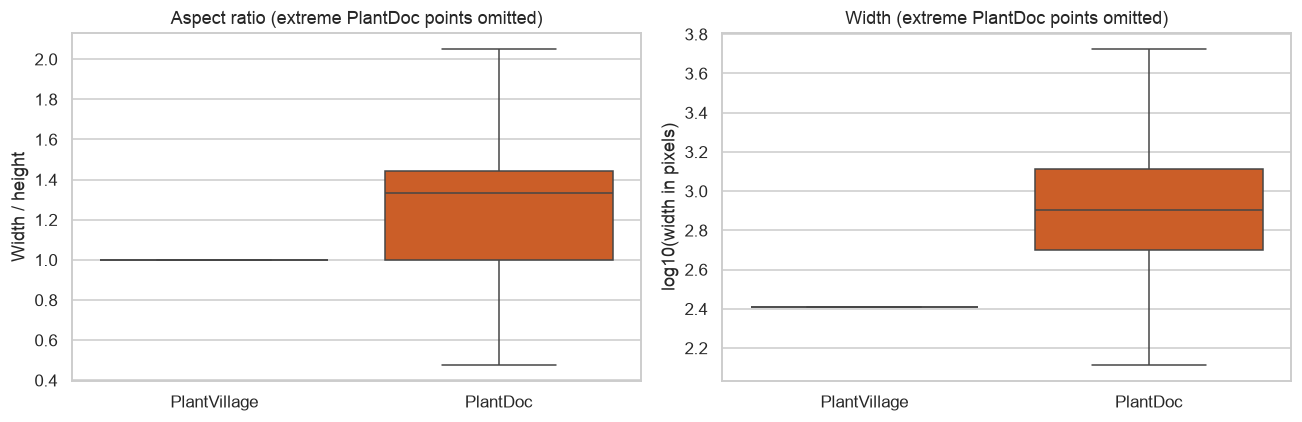

In [4]:
def scan_geometry(paths):
    rows = []
    failed = 0
    for raw in paths:
        path = ROOT / raw
        try:
            with Image.open(path) as image:
                width, height = image.size
                mode = image.mode
                orientation = int(image.getexif().get(0x0112) or 1)
        except OSError:
            failed += 1
            continue
        if orientation in (5, 6, 7, 8):  # rotated a quarter turn: swap
            width, height = height, width
        rows.append((raw, width, height, mode, orientation, path.stat().st_size))
    frame = pd.DataFrame(rows, columns=["path", "width", "height", "mode", "orientation", "bytes"])
    frame["aspect"] = frame["width"] / frame["height"]
    return frame, failed


pv_geom, pv_failed = scan_geometry(plantvillage["path"])
pd_geom, pd_failed = scan_geometry(plantdoc["path"])
print(f"PlantVillage images whose header cannot be read: {pv_failed}")
print(f"PlantDoc images whose header cannot be read: {pd_failed}")
print(f"PlantDoc images with an EXIF rotation or mirror (orientation 2-8): {int((pd_geom['orientation'] > 1).sum())}")


def geometry_summary(frame, name):
    square_256 = ((frame["width"] == 256) & (frame["height"] == 256)).mean()
    return {
        "dataset": name,
        "images": len(frame),
        "width_median": frame["width"].median(),
        "height_median": frame["height"].median(),
        "width_min": int(frame["width"].min()),
        "width_max": int(frame["width"].max()),
        "height_min": int(frame["height"].min()),
        "height_max": int(frame["height"].max()),
        "aspect_median": round(float(frame["aspect"].median()), 3),
        "aspect_p05": round(float(frame["aspect"].quantile(0.05)), 3),
        "aspect_p95": round(float(frame["aspect"].quantile(0.95)), 3),
        "share_256x256": round(float(square_256), 4),
        "file_kb_median": round(frame["bytes"].median() / 1024, 1),
        "modes": ", ".join(f"{mode}={count}" for mode, count in frame["mode"].value_counts().items()),
    }


geometry = pd.DataFrame([geometry_summary(pv_geom, "PlantVillage"), geometry_summary(pd_geom, "PlantDoc")])
display(geometry.T)

geo_plot = pd.concat(
    [pv_geom.assign(dataset="PlantVillage"), pd_geom.assign(dataset="PlantDoc")],
    ignore_index=True,
)
geo_plot["log10_width"] = np.log10(geo_plot["width"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, column, ylabel, title in (
    (axes[0], "aspect", "Width / height", "Aspect ratio (extreme PlantDoc points omitted)"),
    (axes[1], "log10_width", "log10(width in pixels)", "Width (extreme PlantDoc points omitted)"),
):
    sns.boxplot(
        data=geo_plot,
        x="dataset",
        y=column,
        hue="dataset",
        palette={"PlantVillage": PV_COLOR, "PlantDoc": PD_COLOR},
        legend=False,
        showfliers=False,
        ax=axis,
    )
    axis.set_xlabel("")
    axis.set_ylabel(ylabel)
    axis.set_title(title)
fig.tight_layout()
show(fig, "geometry")

## Example images

One random image per class, then four photos that `leaf-map.json` assigns to the same tomato leaf. Since the split is by leaf, all four are in the same split.

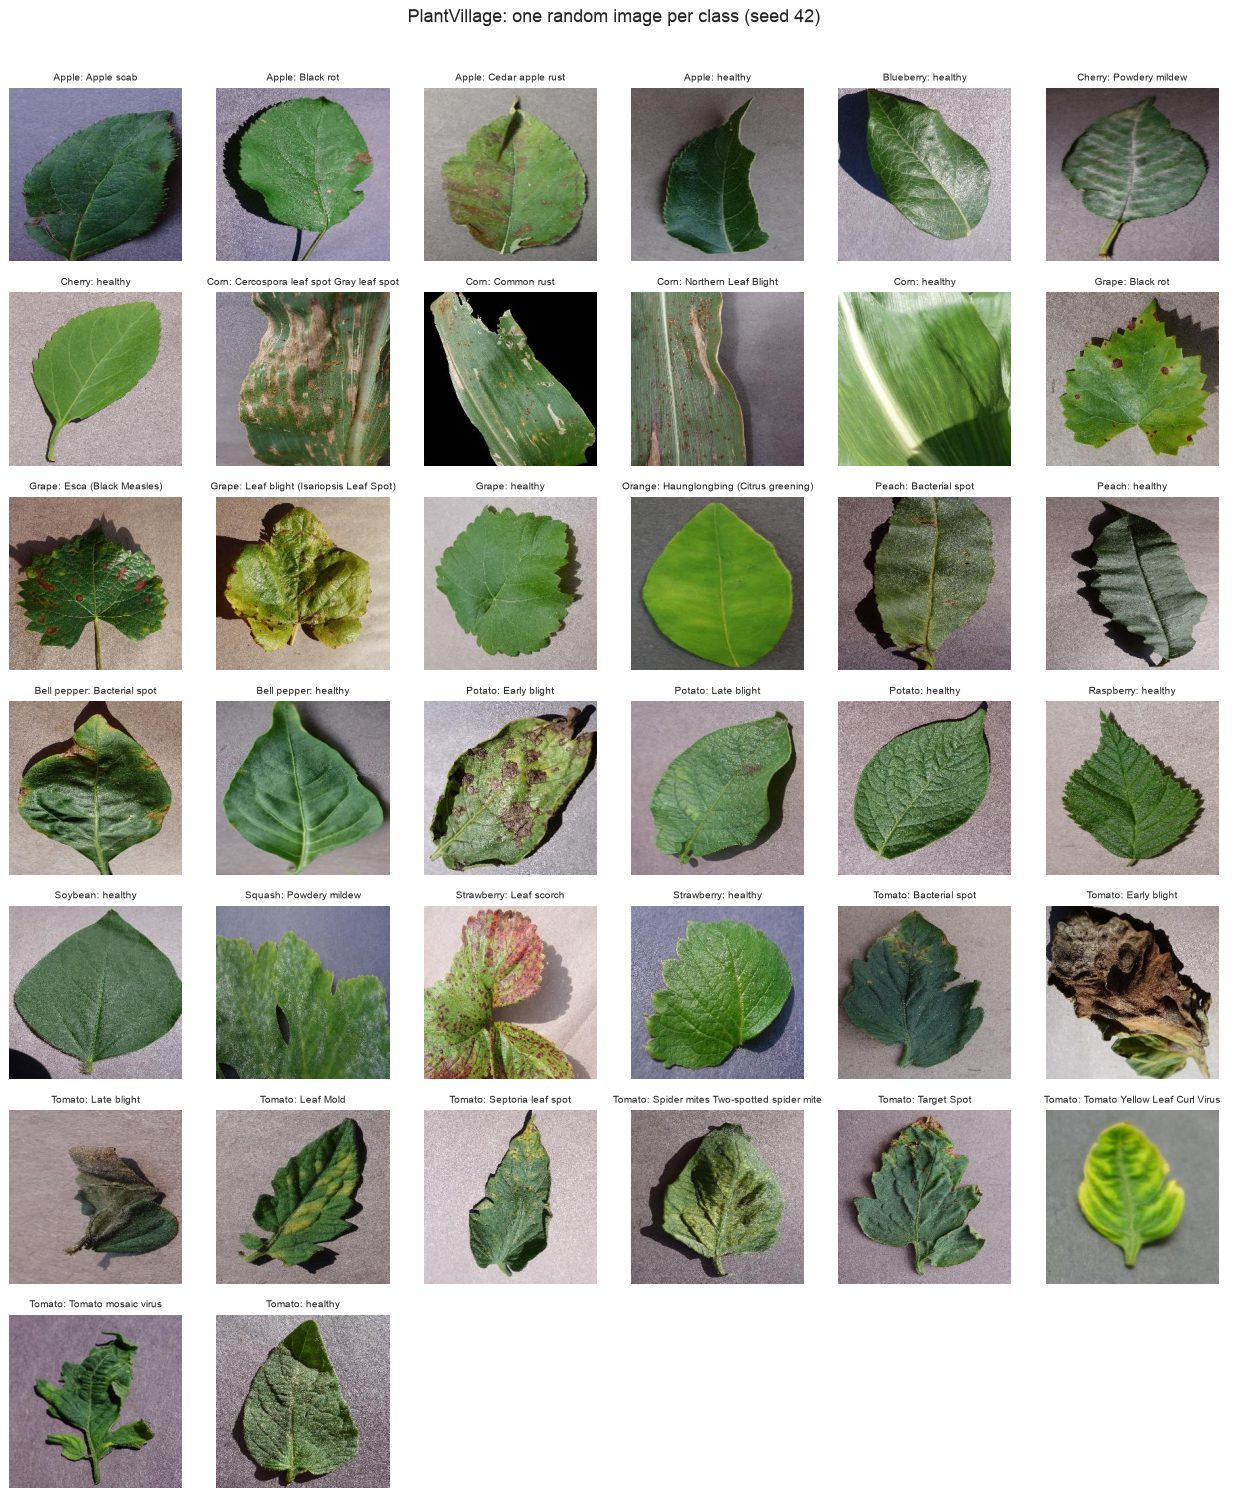

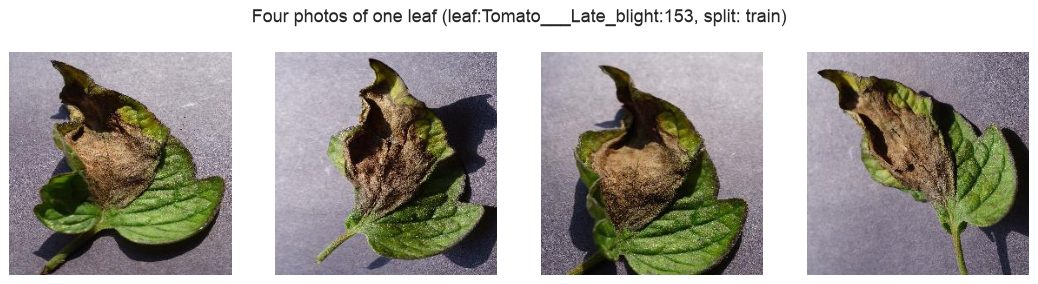

In [5]:
def choose_one(frame, label):
    pool = frame.loc[frame["label"] == label, "path"].to_numpy()
    return str(RNG.choice(pool))


labels = sorted(plantvillage["label"].unique())
columns = 6
rows = int(np.ceil(len(labels) / columns))
fig, axes = plt.subplots(rows, columns, figsize=(14, 2.35 * rows))
for axis, label in zip(axes.ravel(), labels):
    axis.imshow(open_upright(choose_one(plantvillage, label)))
    axis.set_title(short_label(label), fontsize=8)
    axis.axis("off")
for axis in axes.ravel()[len(labels) :]:
    axis.axis("off")
fig.suptitle("PlantVillage: one random image per class (seed 42)", y=1.01)
fig.tight_layout()
show(fig, "plantvillage_one_per_class", photo=True)

# Four photos of the same leaf.
focus = "Tomato___Late_blight"
leaf_sizes = plantvillage[(plantvillage["label"] == focus) & plantvillage["group"].str.startswith("leaf:")]["group"].value_counts()
leaf = str(RNG.choice(leaf_sizes[leaf_sizes >= 4].index.to_numpy()))
one_leaf = plantvillage[plantvillage["group"] == leaf].sort_values("path")
picks = one_leaf["path"].head(4).tolist()
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for axis, raw in zip(axes, picks):
    axis.imshow(open_upright(raw))
    axis.axis("off")
fig.suptitle(f"Four photos of one leaf ({leaf}, split: {', '.join(sorted(set(one_leaf['split'])))})")
fig.tight_layout()
show(fig, "plantvillage_one_leaf", photo=True)

## Per-crop breakdown

Several crops only have a healthy class or only a diseased one. Some PlantVillage classes have no PlantDoc photos at all (listed below and in `data/plantdoc_label_map.csv`). That includes tomato spider mites, whose two PlantDoc images were excluded because they are comparison charts.

,crop,images,classes,healthy_images,diseased_images,healthy_share
0,Tomato,18160,10,1591,16569,0.088
1,Orange,5507,1,0,5507,0.000
2,Soybean,5090,1,5090,0,1.000
3,Grape,4062,4,423,3639,0.104
4,Corn,3852,4,1162,2690,0.302
5,Apple,3171,4,1645,1526,0.519
6,Peach,2657,2,360,2297,0.135
7,Bell pepper,2475,2,1478,997,0.597
8,Potato,2152,3,152,2000,0.071
9,Cherry,1906,2,854,1052,0.448


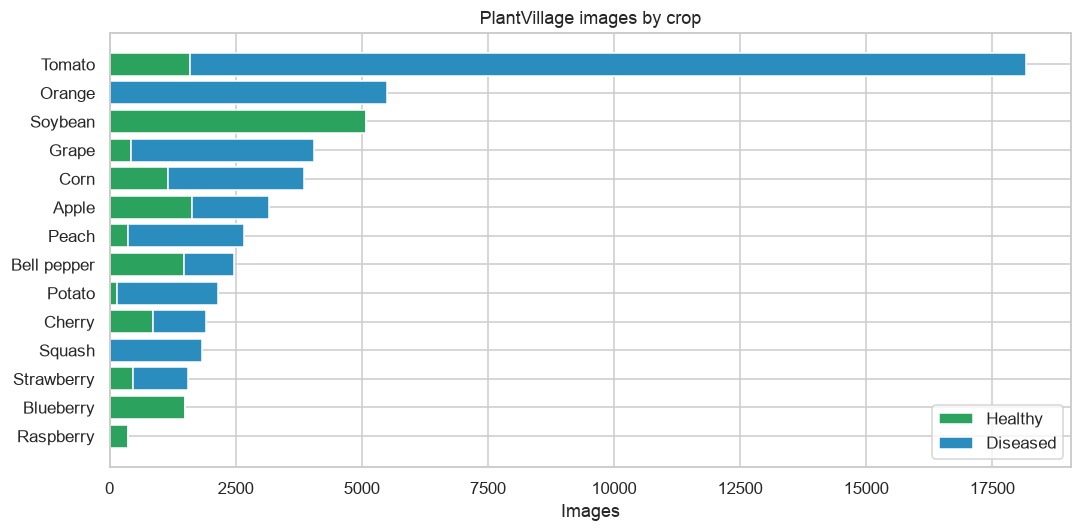

PlantVillage classes with no PlantDoc field photos:


,plantvillage_label,status,notes
0,Tomato___Spider_mites Two-spotted_spider_mite,no_usable_images,"Both PlantDoc images are labeled comparison panels (spot, speck, early blight and mite damage; c..."
1,Apple___Black_rot,unmapped,No apple black-rot class in PlantDoc.
2,Cherry_(including_sour)___Powdery_mildew,unmapped,PlantDoc cherry images are healthy leaves only.
3,Corn_(maize)___healthy,unmapped,PlantDoc has diseased corn leaves but no healthy corn class.
4,Grape___Esca_(Black_Measles),unmapped,No esca / black-measles class in PlantDoc.
5,Grape___Leaf_blight_(Isariopsis_Leaf_Spot),unmapped,No grape leaf-blight class in PlantDoc.
6,Orange___Haunglongbing_(Citrus_greening),unmapped,PlantDoc does not include citrus. Spelling Haunglongbing is the dataset's.
7,Peach___Bacterial_spot,unmapped,PlantDoc peach images are healthy leaves only.
8,Potato___healthy,unmapped,PlantDoc has early and late blight but no healthy potato class.
9,Strawberry___Leaf_scorch,unmapped,"PlantDoc strawberry images are healthy leaves, not leaf scorch."


In [6]:
crop_rows = plantvillage.copy()
crop_rows["crop"] = crop_rows["label"].map(display_crop)
crop_rows["healthy"] = crop_rows["label"].map(is_healthy)
per_crop = (
    crop_rows.groupby("crop")
    .agg(
        images=("path", "size"),
        classes=("label", "nunique"),
        healthy_images=("healthy", "sum"),
    )
    .reset_index()
    .sort_values(["images", "crop"], ascending=[False, True])
)
per_crop["diseased_images"] = per_crop["images"] - per_crop["healthy_images"]
per_crop["healthy_share"] = (per_crop["healthy_images"] / per_crop["images"]).round(3)
display(per_crop.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(10, 5))
plot_crop = per_crop.iloc[::-1]
ax.barh(plot_crop["crop"], plot_crop["healthy_images"], color=HEALTHY_COLOR, label="Healthy")
ax.barh(
    plot_crop["crop"],
    plot_crop["diseased_images"],
    left=plot_crop["healthy_images"],
    color=PV_COLOR,
    label="Diseased",
)
ax.set_xlabel("Images")
ax.set_title("PlantVillage images by crop")
ax.legend()
fig.tight_layout()
show(fig, "plantvillage_crops")

print("PlantVillage classes with no PlantDoc field photos:")
display(label_map.loc[label_map["status"] != "mapped", ["plantvillage_label", "status", "notes"]].reset_index(drop=True))

## Color and brightness

Computed on 25 images per class (seed 42), shrunk to 96 px on the long side.

brightness        saturation           red          green         \
                 median    std     median   std  median    std  median    std   
dataset                                                                         
PlantDoc         110.30  40.48       0.39  0.16  113.00  43.63  134.43  38.38   
PlantVillage     117.27  17.83       0.25  0.07  119.77  18.64  125.79  19.03   

                blue         
              median    std  
dataset                      
PlantDoc       89.88  46.06  
PlantVillage  107.57  19.64

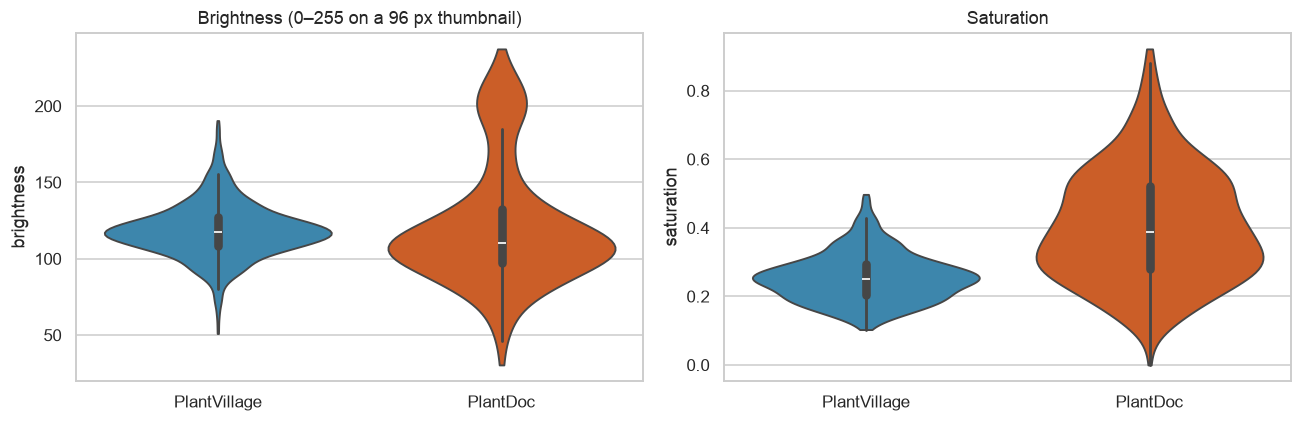

In [7]:
def sample_paths(frame, per_class):
    chosen = []
    for _label, group in frame.groupby("label"):
        pool = group["path"].to_numpy()
        take = min(per_class, len(pool))
        chosen.extend(RNG.choice(pool, size=take, replace=False).tolist())
    return chosen


def color_stats(paths, dataset):
    rows = []
    for raw in paths:
        image = open_upright(raw, max_side=96)
        pixels = np.asarray(image, dtype=np.float32)
        mean_rgb = pixels.mean(axis=(0, 1))
        peak = pixels.max(axis=2)
        floor = pixels.min(axis=2)
        saturation = np.where(peak <= 0, 0, (peak - floor) / np.maximum(peak, 1e-6)).mean()
        rows.append(
            {
                "dataset": dataset,
                "brightness": float(pixels.mean()),
                "saturation": float(saturation),
                "red": float(mean_rgb[0]),
                "green": float(mean_rgb[1]),
                "blue": float(mean_rgb[2]),
            }
        )
    return pd.DataFrame(rows)


color = pd.concat(
    [
        color_stats(sample_paths(plantvillage, 25), "PlantVillage"),
        color_stats(sample_paths(plantdoc, 25), "PlantDoc"),
    ],
    ignore_index=True,
)
summary = color.groupby("dataset")[["brightness", "saturation", "red", "green", "blue"]].agg(["median", "std"]).round(2)
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
palette = {"PlantVillage": PV_COLOR, "PlantDoc": PD_COLOR}
sns.violinplot(data=color, x="dataset", y="brightness", hue="dataset", palette=palette, legend=False, ax=axes[0], cut=0)
axes[0].set_title("Brightness (0–255 on a 96 px thumbnail)")
axes[0].set_xlabel("")
sns.violinplot(data=color, x="dataset", y="saturation", hue="dataset", palette=palette, legend=False, ax=axes[1], cut=0)
axes[1].set_title("Saturation")
axes[1].set_xlabel("")
fig.tight_layout()
show(fig, "color_brightness")

## PlantVillage vs PlantDoc

Top row: PlantVillage. Bottom row: a PlantDoc photo with the same label.

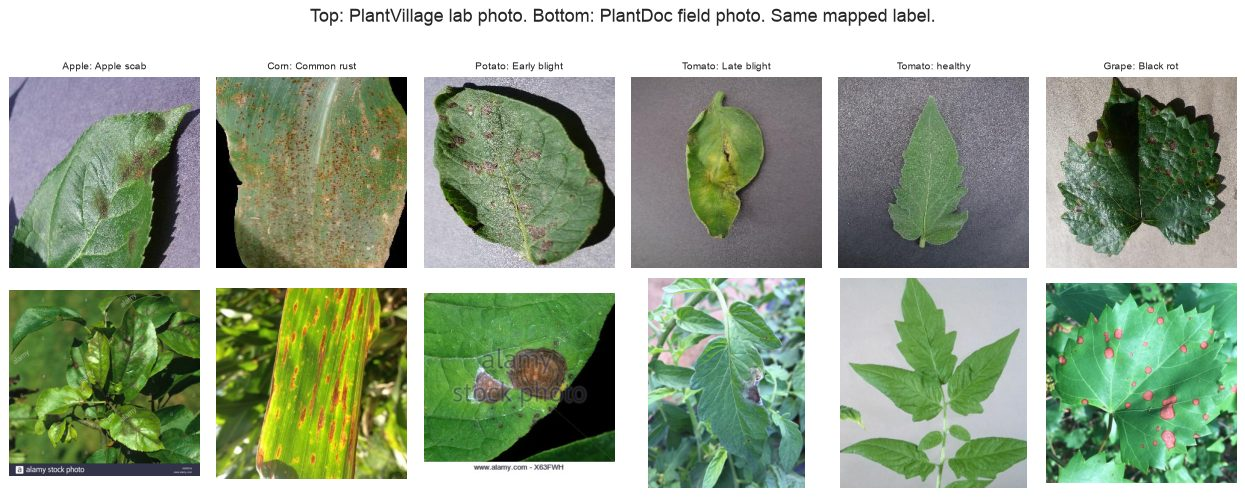

In [8]:
pair_labels = [
    "Apple___Apple_scab",
    "Corn_(maize)___Common_rust_",
    "Potato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___healthy",
    "Grape___Black_rot",
]
fig, axes = plt.subplots(2, len(pair_labels), figsize=(14, 5.4))
for column, label in enumerate(pair_labels):
    for row, frame in enumerate((plantvillage, plantdoc)):
        axes[row, column].imshow(open_upright(choose_one(frame, label), max_side=400))
        axes[row, column].axis("off")
        if row == 0:
            axes[row, column].set_title(short_label(label), fontsize=8)
fig.suptitle("Top: PlantVillage lab photo. Bottom: PlantDoc field photo. Same mapped label.", y=1.02)
fig.tight_layout()
show(fig, "plantvillage_vs_plantdoc", photo=True)

## Duplicates and repeated leaves

Three checks:

1. How often PlantVillage has several photos of one leaf or byte-identical copies, and whether those cross the old and new splits.
2. Whether PlantDoc has the same photo more than once, possibly under different labels.
3. Whether any PlantDoc photo also appears in PlantVillage.

Exact copies are found with MD5, and near copies (resized, re-encoded, different watermark) with a 64-bit perceptual hash. Different stock photos on a white background can also have a small pHash distance, so every PlantDoc pair within 8 bits was checked by eye before excluding anything. The hashing code is in `src/data/duplicates.py`.

In [9]:
from src.data.duplicates import connected_groups, hash_images, near_pairs, nearest

pv_hash = hash_images(plantvillage["path"].tolist(), ROOT)
pv = plantvillage.merge(pv_hash, on="path", validate="one_to_one")

# 1a. Byte-identical PlantVillage files.
imagelevel = pd.concat(
    [pd.read_csv(ROOT / "data" / "splits" / f"{name}_imagelevel.csv").assign(old_split=name) for name in ("train", "val", "test")],
    ignore_index=True,
)
pv = pv.merge(imagelevel[["path", "old_split"]], on="path", validate="one_to_one")
copies = pv[pv.duplicated("md5", keep=False)]
copy_groups = copies.groupby("md5")
print(f"Byte-identical PlantVillage groups: {copy_groups.ngroups} ({len(copies)} files), "
      f"classes: {', '.join(sorted(copies['label'].map(short_label).unique()))}")
print(f"  groups split across train/val/test, old image-level split: {int((copy_groups['old_split'].nunique() > 1).sum())}")
print(f"  groups split across train/val/test, leaf-grouped split:    {int((copy_groups['split'].nunique() > 1).sum())}")
print(f"  groups whose copies share one group id: {int((copy_groups['group'].nunique() == 1).sum())} of {copy_groups.ngroups}")

Byte-identical PlantVillage groups: 21 (42 files), classes: Apple: healthy, Tomato: Late blight, Tomato: healthy
  groups split across train/val/test, old image-level split: 12
  groups split across train/val/test, leaf-grouped split:    0
  groups whose copies share one group id: 21 of 21


Images with a leaf id from leaf-map.json: 42,511 of 54,305 (78.3%) on 7,945 leaves
Photos per known leaf: median 4, mean 5.4, max 33; leaves with 2+ photos: 99.8%
Classes with no leaf ids: Corn: healthy, Tomato: Tomato mosaic virus, Squash: Powdery mildew, Grape: healthy, Corn: Cercospora leaf spot Gray leaf spot, Corn: Common rust, Corn: Northern Leaf Blight


,split,part,images,share_with_train_leaf
0,image-level (old),val,8146,76.5
1,image-level (old),test,8146,76.7
2,leaf-grouped (new),val,8144,0.0
3,leaf-grouped (new),test,8147,0.0


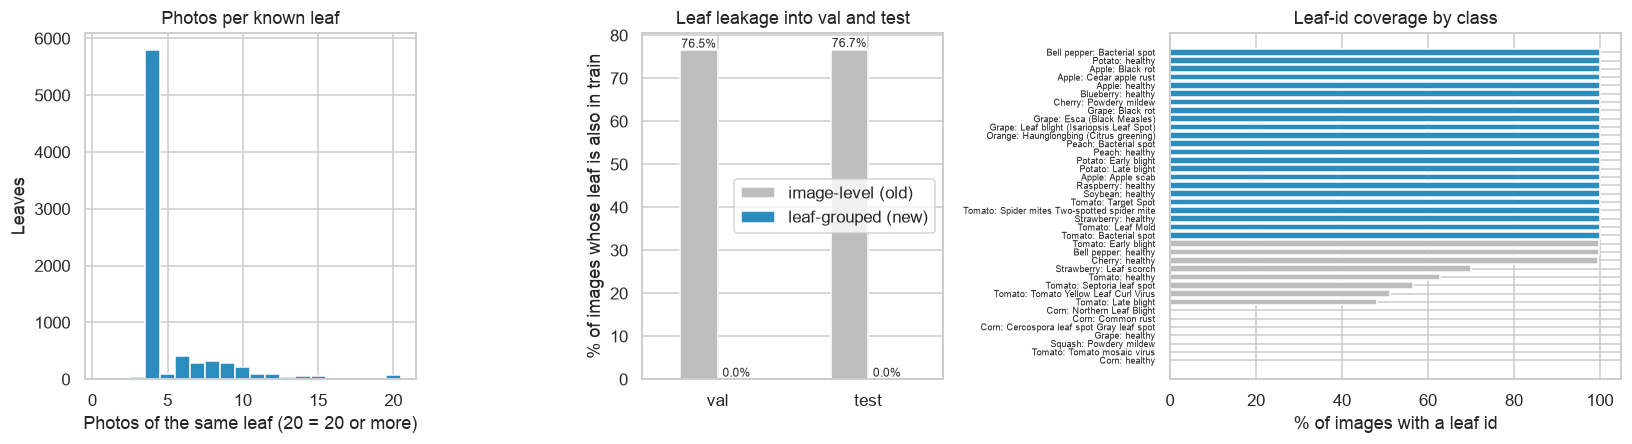

In [10]:
# 1b. Leaves photographed more than once.
has_leaf = pv["group"].str.startswith("leaf:")
per_leaf = pv.loc[has_leaf, "group"].value_counts()
coverage = has_leaf.groupby(pv["label"]).mean().sort_values()
print(f"Images with a leaf id from leaf-map.json: {int(has_leaf.sum()):,} of {len(pv):,} ({has_leaf.mean():.1%}) on {len(per_leaf):,} leaves")
print(f"Photos per known leaf: median {per_leaf.median():.0f}, mean {per_leaf.mean():.1f}, max {per_leaf.max()}; "
      f"leaves with 2+ photos: {(per_leaf > 1).mean():.1%}")
print(f"Classes with no leaf ids: {', '.join(coverage[coverage == 0].index.map(short_label))}")

# How much of val/test shared a leaf with train?
leaf_of = pv.set_index("path")["group"].where(has_leaf.to_numpy())
rows = []
for split_column, name in (("old_split", "image-level (old)"), ("split", "leaf-grouped (new)")):
    train_leaves = set(leaf_of[pv.loc[pv[split_column] == "train", "path"]].dropna())
    for part in ("val", "test"):
        part_paths = pv.loc[pv[split_column] == part, "path"]
        shared = leaf_of[part_paths].isin(train_leaves)
        rows.append({"split": name, "part": part, "images": len(part_paths), "share_with_train_leaf": shared.mean()})
leakage = pd.DataFrame(rows)
display(leakage.assign(share_with_train_leaf=lambda f: (f["share_with_train_leaf"] * 100).round(1)))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.1, 1, 1.5]})
axes[0].hist(per_leaf.clip(upper=20), bins=np.arange(1, 22) - 0.5, color=PV_COLOR)
axes[0].set_xlabel("Photos of the same leaf (20 = 20 or more)")
axes[0].set_ylabel("Leaves")
axes[0].set_title("Photos per known leaf")
plot = leakage.pivot(index="part", columns="split", values="share_with_train_leaf").loc[["val", "test"]] * 100
plot[["image-level (old)", "leaf-grouped (new)"]].plot.bar(ax=axes[1], color=[MUTED_COLOR, PV_COLOR], rot=0)
axes[1].set_ylabel("% of images whose leaf is also in train")
axes[1].set_xlabel("")
axes[1].set_title("Leaf leakage into val and test")
axes[1].legend(title="")
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%", fontsize=8)
cov = (coverage * 100).rename(index=short_label)
axes[2].barh(cov.index, cov.to_numpy(), color=[MUTED_COLOR if v < 100 else PV_COLOR for v in cov.to_numpy()])
axes[2].set_xlabel("% of images with a leaf id")
axes[2].set_title("Leaf-id coverage by class")
axes[2].tick_params(axis="y", labelsize=6)
fig.tight_layout()
show(fig, "leaf_groups_and_leakage")

Classes without leaf ids (all of corn, healthy grape, squash, tomato mosaic and parts of five others) are grouped by file name only, so repeat photos can still cross splits there.

### PlantDoc duplicates

Hash every PlantDoc image (kept and excluded), join pairs within 8 bits into groups, and count the groups with more than one label.

In [11]:
pd_all = pd.concat(
    [plantdoc.assign(excluded=False), plantdoc_excluded[["path", "label", "source_split", "reason"]].assign(excluded=True)],
    ignore_index=True,
).sort_values("path").reset_index(drop=True)
pd_all["folder"] = pd_all["path"].str.split("/").str[4]
pd_all = pd_all.merge(hash_images(pd_all["path"].tolist(), ROOT), on="path", validate="one_to_one")

# These two pairs are similar stock photos, not the same photo (checked by eye).
DIFFERENT_PHOTOS = {
    ("data/raw/plantdoc/train/Apple leaf/depositphotos_45748597-stock-photo-ripe-apple-with-leaf.jpg",
     "data/raw/plantdoc/train/Apple leaf/depositphotos_6657863-stock-photo-single-red-apple-with-leaf.jpg"),
    ("data/raw/plantdoc/train/Peach leaf/peach-with-leaf-isolated-on-white-picture-id466696757.jpg",
     "data/raw/plantdoc/train/Peach leaf/stock-photo-peach-with-leaf-isolated-on-white-168119267.jpg"),
}
candidates = near_pairs(pd_all["phash"].tolist(), max_distance=8)
names = pd_all["path"].to_numpy()
apart = [(names[i], names[j]) in DIFFERENT_PHOTOS for i, j in zip(candidates["i"], candidates["j"])]
near = candidates[~np.array(apart)].copy()
near["exact"] = pd_all["md5"].to_numpy()[near["i"]] == pd_all["md5"].to_numpy()[near["j"]]
pd_all["dup_group"] = connected_groups(len(pd_all), list(zip(near["i"], near["j"])))
in_group = pd_all[pd_all["dup_group"] >= 0]
labels_per_group = in_group.groupby("dup_group")["label"].nunique()
crops_per_group = in_group.assign(crop=in_group["label"].map(display_crop)).groupby("dup_group")["crop"].nunique()
print(f"PlantDoc images: {len(pd_all):,}")
print(f"Pairs at pHash distance <= 8: {len(candidates)}; checked by eye and found to be different photos: {sum(apart)}")
print(f"Same-photo pairs: {len(near)} (byte-identical: {int(near['exact'].sum())})")
print(f"Duplicate groups: {in_group['dup_group'].nunique()} covering {len(in_group)} images")
print(f"  groups with conflicting labels: {int((labels_per_group > 1).sum())}, of which across crops: {int((crops_per_group > 1).sum())}")
print(f"  groups spanning PlantDoc's own train/ and test/ folders: {int((in_group.groupby('dup_group')['source_split'].nunique() > 1).sum())}")
kept_index = pd_all.index[~pd_all["excluded"]]
remaining = near[near["i"].isin(kept_index) & near["j"].isin(kept_index)]
print(f"Same-photo pairs left among kept images: {len(remaining)}")
print(f"Byte-identical files left among kept images: {int(pd_all.loc[kept_index, 'md5'].duplicated().sum())}")

reasons = plantdoc_excluded.pivot_table(index="label", columns="reason", values="path", aggfunc="count", fill_value=0)
reasons["total"] = reasons.sum(axis=1)
display(reasons.sort_values("total", ascending=False).rename(index=short_label))

PlantDoc images: 2,578
Pairs at pHash distance <= 8: 83; checked by eye and found to be different photos: 2
Same-photo pairs: 81 (byte-identical: 12)
Duplicate groups: 77 covering 156 images
  groups with conflicting labels: 33, of which across crops: 14
  groups spanning PlantDoc's own train/ and test/ folders: 15
Same-photo pairs left among kept images: 0
Byte-identical files left among kept images: 0


reason,conflicting_duplicate,duplicate,file_name,total
label,,,,
Corn: Northern Leaf Blight,2,2,57,61
Corn: Common rust,0,1,42,43
Potato: Early blight,12,0,24,36
Tomato: Bacterial spot,2,2,22,26
Tomato: Septoria leaf spot,5,4,10,19
Raspberry: healthy,0,1,10,11
Tomato: Early blight,6,2,3,11
Tomato: Late blight,5,4,1,10
Potato: Late blight,6,1,2,9


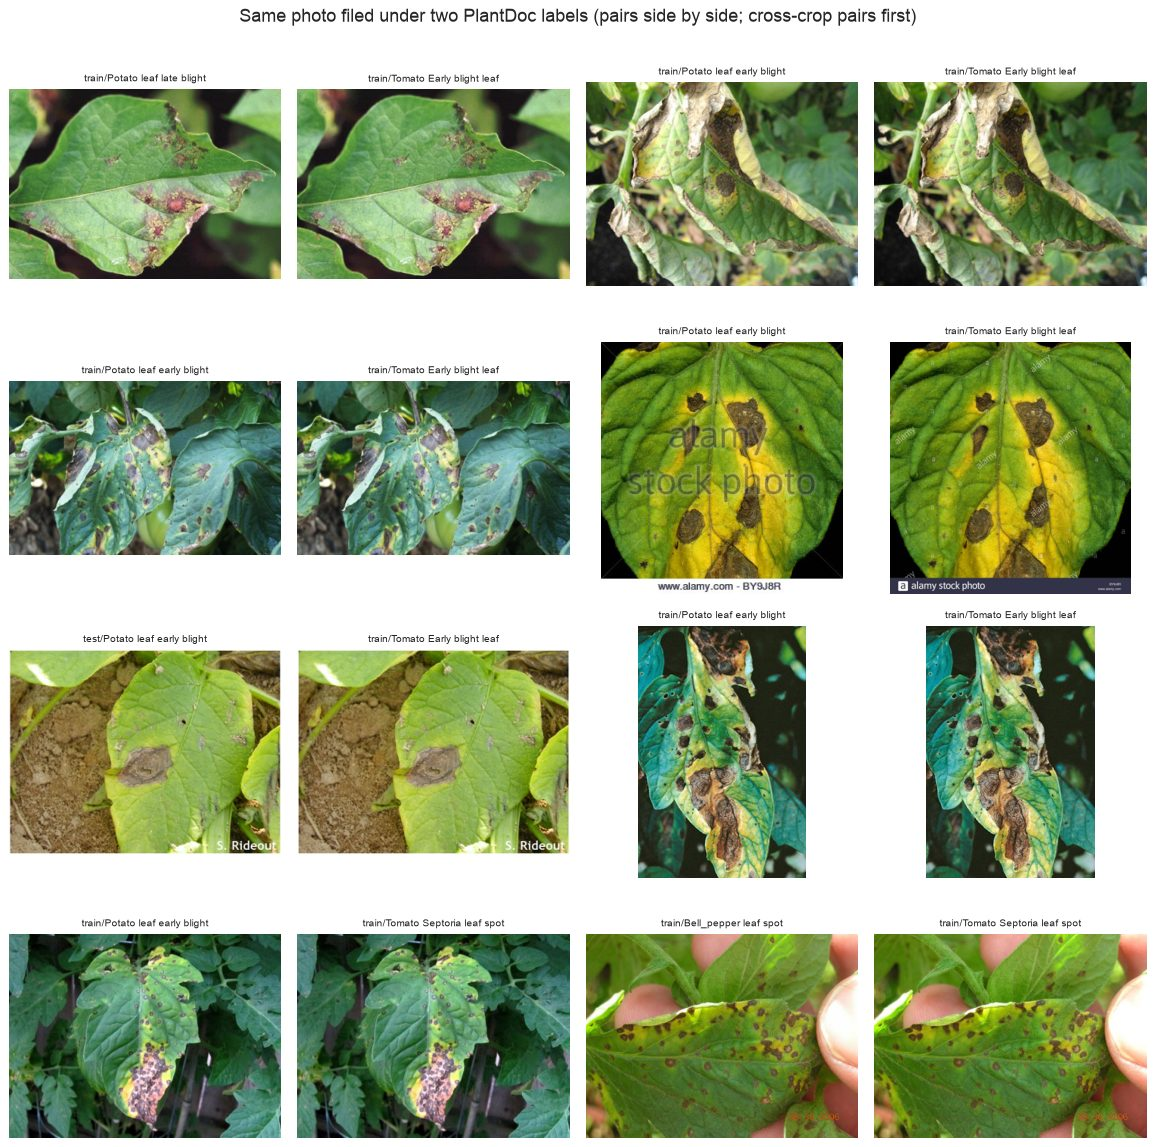

In [12]:
# Same photo, different PlantDoc folders.
conflicts = in_group[in_group["dup_group"].isin(labels_per_group[labels_per_group > 1].index)]
cross_crop = crops_per_group[crops_per_group > 1].index
order = sorted(conflicts["dup_group"].unique(), key=lambda g: (g not in cross_crop, g))[:8]
fig, axes = plt.subplots(4, 4, figsize=(13, 13))
for slot, group_id in enumerate(order):
    members = conflicts[conflicts["dup_group"] == group_id].drop_duplicates("label").head(2)
    for offset, (_, member) in enumerate(members.iterrows()):
        axis = axes.ravel()[slot * 2 + offset]
        axis.imshow(open_upright(member["path"], max_side=360))
        axis.set_title(f"{member['source_split']}/{member['folder']}", fontsize=8)
        axis.axis("off")
fig.suptitle("Same photo filed under two PlantDoc labels (pairs side by side; cross-crop pairs first)", y=1.0)
fig.tight_layout()
show(fig, "plantdoc_conflicting_duplicates", photo=True)

How these were handled (see `data/plantdoc_excluded.csv`):

- `duplicate`: extra copies of a photo with a single label. We keep the copy from PlantDoc's `test/` folder if there is one, otherwise the largest.
- `conflicting_duplicate`: the same photo under different labels. One copy is kept only if a file name makes the label clear (for example `Late+blight+on+potato.jpg`); otherwise all copies are dropped.
- `file_name`: the file name points to a different disease, crop or plant, for example southern rust in the corn rust folder or iron deficiency in a healthy folder. File names come from the source websites, so this is a hint, not a verified label.

### Overlap with PlantVillage

Nearest PlantVillage image (by pHash) for each kept PlantDoc photo:

Byte-identical PlantDoc/PlantVillage files: 0
PlantDoc photos whose nearest PlantVillage image is within d bits: {0: 0, 2: 0, 4: 1, 6: 7, 8: 31, 10: 123}


,path,label,nearest_pv,nearest_pv_label,distance
0,data/raw/plantdoc/train/Tomato leaf late blight/TomatoLateBlightTop.jpg,Tomato___Late_blight,data/raw/plantvillage/color/Apple___healthy/f09b090f-bff1-4fc9-87ad-1b9e05373698___RS_HL 6035.JPG,Apple___healthy,4
1,data/raw/plantdoc/test/Apple leaf/apple-leaf-closeup-37636177.jpg,Apple___healthy,data/raw/plantvillage/color/Blueberry___healthy/bafd9520-a306-441b-8f0f-8fdd5ff0f3d3___RS_HL 237...,Blueberry___healthy,6
2,data/raw/plantdoc/train/Apple leaf/depositphotos_30057617-Green-leaf-of-apple-tree.jpg,Apple___healthy,data/raw/plantvillage/color/Apple___Black_rot/888c8b6e-55cb-4492-b489-22f3624f1c39___JR_FrgE.S 8...,Apple___Black_rot,6
3,data/raw/plantdoc/train/Apple leaf/depositphotos_45748597-stock-photo-ripe-apple-with-leaf.jpg,Apple___healthy,data/raw/plantvillage/color/Soybean___healthy/8e3f6573-c338-48e5-bfba-257daff8e52e___RS_HL 5048.JPG,Soybean___healthy,6


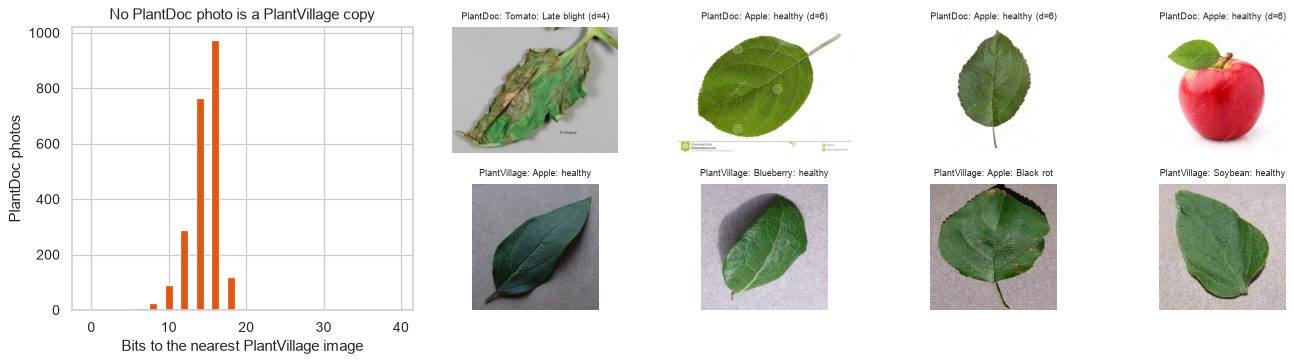

In [13]:
pd_kept = pd_all[~pd_all["excluded"]].reset_index(drop=True)
nearest_index, nearest_distance = nearest(pd_kept["phash"].tolist(), pv["phash"].tolist())
pd_kept["nearest_pv"] = pv["path"].to_numpy()[nearest_index]
pd_kept["nearest_pv_label"] = pv["label"].to_numpy()[nearest_index]
pd_kept["distance"] = nearest_distance
print(f"Byte-identical PlantDoc/PlantVillage files: {len(set(pd_kept['md5']) & set(pv['md5']))}")
print("PlantDoc photos whose nearest PlantVillage image is within d bits:",
      {d: int((pd_kept["distance"] <= d).sum()) for d in (0, 2, 4, 6, 8, 10)})
closest = pd_kept.sort_values(["distance", "path"]).head(4)
display(closest[["path", "label", "nearest_pv", "nearest_pv_label", "distance"]].reset_index(drop=True))

fig = plt.figure(figsize=(15, 4.2))
grid = fig.add_gridspec(2, 5, width_ratios=[1.6, 1, 1, 1, 1])
hist = fig.add_subplot(grid[:, 0])
hist.hist(pd_kept["distance"], bins=np.arange(0, 41) - 0.5, color=PD_COLOR)
hist.set_xlabel("Bits to the nearest PlantVillage image")
hist.set_ylabel("PlantDoc photos")
hist.set_title("No PlantDoc photo is a PlantVillage copy")
for column, (_, row) in enumerate(closest.iterrows(), start=1):
    for line, (raw, label) in enumerate(((row["path"], row["label"]), (row["nearest_pv"], row["nearest_pv_label"]))):
        axis = fig.add_subplot(grid[line, column])
        axis.imshow(open_upright(raw, max_side=256))
        axis.set_title(f"{'PlantDoc' if line == 0 else 'PlantVillage'}: {short_label(label)}" + (f" (d={row['distance']})" if line == 0 else ""), fontsize=7)
        axis.axis("off")
fig.tight_layout()
show(fig, "plantdoc_nearest_plantvillage", photo=True)

## PlantDoc class counts

PlantDoc is much smaller than PlantVillage but close to balanced. Most of its images come from PlantDoc's own `train/` folder, which is fine since we don't train on PlantDoc.

source_split,test,train,kept,excluded
plantvillage_label,,,,
Tomato: Septoria leaf spot,10,122,132,19
Corn: Northern Leaf Blight,6,125,131,61
Squash: Powdery mildew,6,118,124,6
Raspberry: healthy,6,102,108,11
Blueberry: healthy,10,98,108,9
Peach: healthy,8,99,107,5
Tomato: Late blight,10,91,101,10
Potato: Late blight,6,90,96,9
Strawberry: healthy,8,85,93,3


PlantDoc kept images: 2,269 in 27 classes; per class min 50, median 84, max 132; largest/smallest 2.6x (PlantVillage: 36.2x)


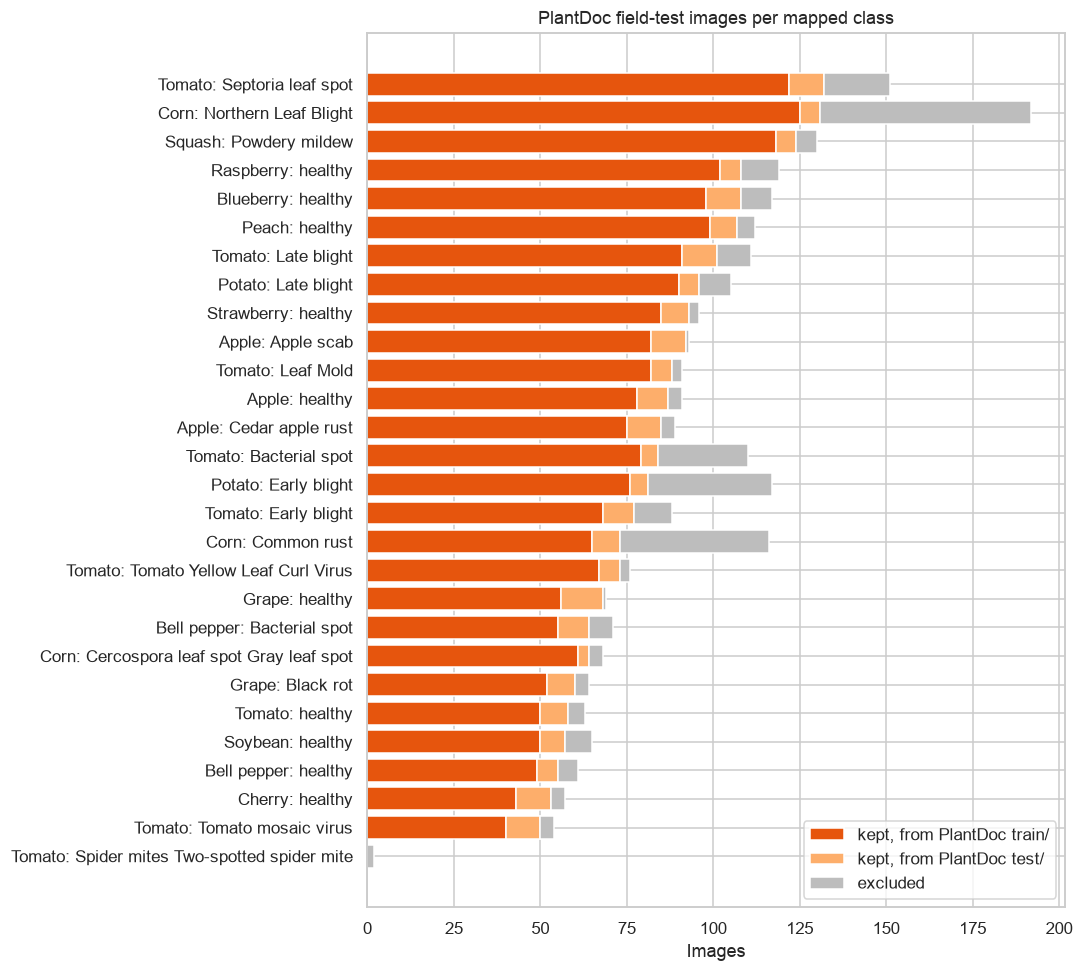

In [14]:
mapped_labels = label_map.loc[label_map["status"] != "unmapped", "plantvillage_label"]
kept_counts = plantdoc.groupby(["label", "source_split"]).size().unstack(fill_value=0).reindex(mapped_labels, fill_value=0)
kept_counts["kept"] = kept_counts.sum(axis=1)
kept_counts["excluded"] = plantdoc_excluded.groupby("label").size().reindex(kept_counts.index, fill_value=0)
kept_counts = kept_counts.sort_values(["kept", "excluded"]).rename(index=short_label)
display(kept_counts.iloc[::-1])
present = kept_counts[kept_counts["kept"] > 0]["kept"]
print(f"PlantDoc kept images: {int(present.sum()):,} in {len(present)} classes; per class min {present.min()}, median {present.median():.0f}, max {present.max()}; "
      f"largest/smallest {present.max() / present.min():.1f}x (PlantVillage: {imbalance_ratio:.1f}x)")

fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(kept_counts.index, kept_counts["train"], color=PD_COLOR, label="kept, from PlantDoc train/")
ax.barh(kept_counts.index, kept_counts["test"], left=kept_counts["train"], color="#fdae6b", label="kept, from PlantDoc test/")
ax.barh(kept_counts.index, kept_counts["excluded"], left=kept_counts["kept"], color=MUTED_COLOR, label="excluded")
ax.set_xlabel("Images")
ax.set_title("PlantDoc field-test images per mapped class")
ax.legend(loc="lower right")
fig.tight_layout()
show(fig, "plantdoc_class_sizes")

## Transform previews

Train images get a random resized crop (70-100% of the area), a flip, up to 15 degrees of rotation and color jitter. Eval images (val, test, PlantDoc) are resized to 256 on the short side and center-cropped to 224. The previews undo the normalization.

Two things show up here: the rotation leaves black corners on training images, and on very wide or tall PlantDoc photos the center crop (red box) cuts off a lot of the image.

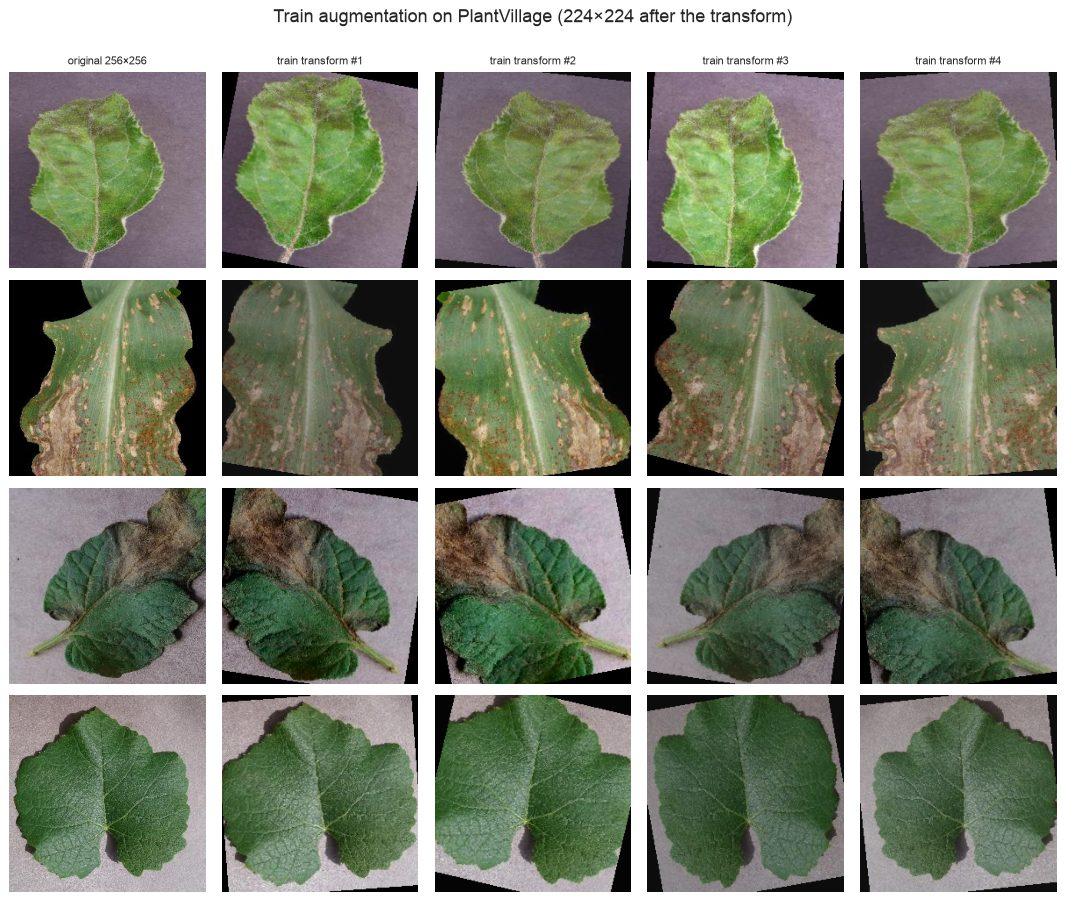

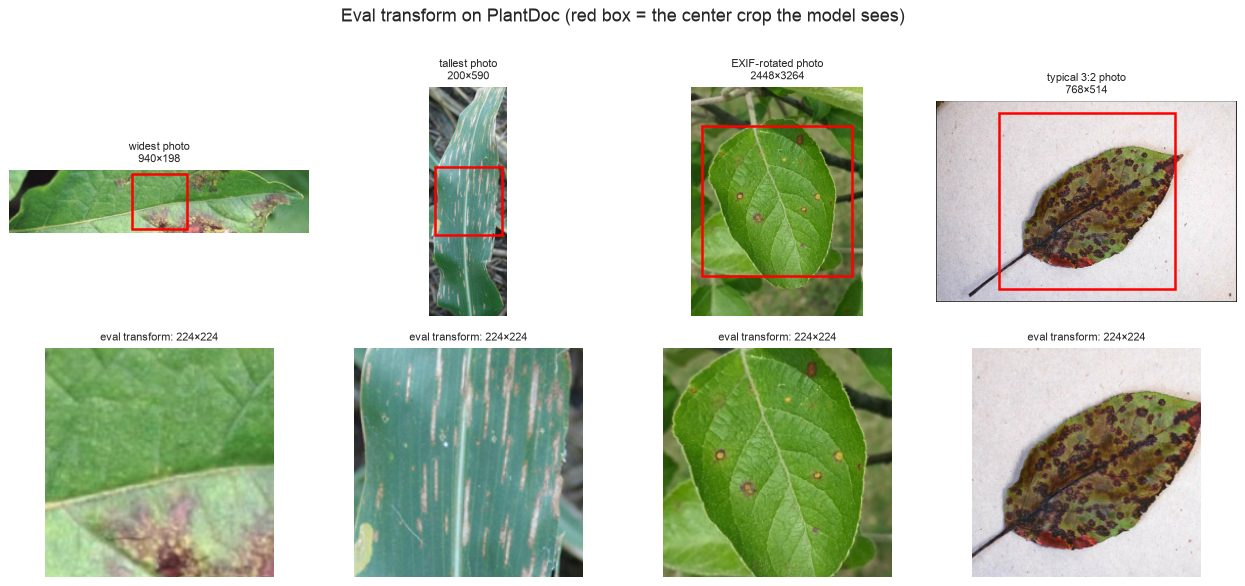

In [15]:
import torch

from src.data.dataset import IMAGENET_MEAN, IMAGENET_STD, PlantDiseaseDataset, build_transforms

mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)


def viewable(tensor):
    return (tensor * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()


torch.manual_seed(42)
train_tf = build_transforms("train")
train_rows = plantvillage[plantvillage["split"] == "train"]
examples = [choose_one(train_rows, label) for label in ("Apple___Apple_scab", "Corn_(maize)___Common_rust_", "Tomato___Late_blight", "Grape___healthy")]
fig, axes = plt.subplots(len(examples), 5, figsize=(12, 10))
for row, raw in enumerate(examples):
    original = open_upright(raw)
    axes[row, 0].imshow(original)
    axes[row, 0].set_title("original 256×256" if row == 0 else "", fontsize=9)
    for column in range(1, 5):
        axes[row, column].imshow(viewable(train_tf(original)))
        if row == 0:
            axes[row, column].set_title(f"train transform #{column}", fontsize=9)
    for axis in axes[row]:
        axis.axis("off")
fig.suptitle("Train augmentation on PlantVillage (224×224 after the transform)", y=1.0)
fig.tight_layout()
show(fig, "transforms_train", photo=True)

widest = pd_geom.nlargest(1, "aspect")["path"].tolist()
tallest = pd_geom.nsmallest(1, "aspect")["path"].tolist()
rotated = pd_geom[pd_geom["orientation"].isin([6, 8])].sort_values("path")["path"].head(1).tolist()
typical = pd_geom[(pd_geom["aspect"] - 1.5).abs() < 0.05].sort_values("path")["path"].head(1).tolist()
field = widest + tallest + rotated + typical
captions = ["widest photo", "tallest photo", "EXIF-rotated photo", "typical 3:2 photo"]
eval_ds = PlantDiseaseDataset(ROOT / "data" / "splits" / "plantdoc_test.csv", transform=build_transforms("plantdoc"))
fig, axes = plt.subplots(2, len(field), figsize=(14, 6.5))
for column, (raw, caption) in enumerate(zip(field, captions)):
    original = open_upright(raw)
    width, height = original.size
    side = 224 * min(width, height) / 256
    left, top = (width - side) / 2, (height - side) / 2
    axes[0, column].imshow(original)
    axes[0, column].add_patch(plt.Rectangle((left, top), side, side, fill=False, edgecolor="red", linewidth=2))
    axes[0, column].set_title(f"{caption}\n{width}×{height}", fontsize=9)
    tensor, _label = eval_ds[eval_ds.paths.index(raw)]
    axes[1, column].imshow(viewable(tensor))
    axes[1, column].set_title("eval transform: 224×224", fontsize=9)
    for axis in axes[:, column]:
        axis.axis("off")
fig.suptitle("Eval transform on PlantDoc (red box = the center crop the model sees)", y=1.0)
fig.tight_layout()
show(fig, "transforms_eval_plantdoc", photo=True)

## Summary

- PlantVillage: 54,305 images in 38 classes, all 256x256. The largest class is citrus greening (5,507) and the smallest is healthy potato (152), about a 36x difference. The three largest classes are 29% of the data.
- Leaf-grouped split: 38,014 / 8,144 / 8,147. No image or leaf group is in two splits, and each class is 68-72% train.
- 78% of the images have a leaf id (7,945 leaves, median 4 photos per leaf). With the old image-level split, 76.5% of val and 76.7% of test images shared a leaf with train; now none do. The 21 groups of byte-identical files are each in a single split (12 of them crossed splits before).
- PlantDoc: 2,269 images in 27 classes after excluding 309 (233 by file name, 42 conflicting duplicates, 34 duplicates), with 50-132 images per class.
- PlantDoc had 77 groups of the same photo, 33 of them under conflicting labels (14 across crops). None are left in the test set.
- No PlantDoc photo is a copy of a PlantVillage image. The closest pairs (4-6 bits apart) are unrelated leaves.
- Kept PlantDoc photos are 115 to 6,000 px wide (median about 800x675), and 27 of them have an EXIF rotation.
- Brightness varies much more in PlantDoc (standard deviation about 40 vs 18), and median saturation is 0.39 vs 0.25 for PlantVillage.
- 11 PlantVillage classes have no PlantDoc photos.

## Notes for modeling and evaluation

PlantVillage is a lab dataset, so a CNN can get very high accuracy partly by using the plain background and then miss the disease in field photos. That is the reason PlantDoc was collected (Singh et al., 2020). Hughes and Salathé (2015) describe the original PlantVillage collection, and Mohanty et al. (2016) published the leaf ids we use for the split.

- Mayur: train on `train.csv` and choose models with `val.csv`. The `fold` column in `train.csv` (folds 6-19) can be used for cross-validation. Don't train on PlantDoc or pick models by their PlantDoc score.
- Eric: report `test.csv` and `plantdoc_test.csv` separately, with macro-F1 and per-class recall. Mention the 11 classes without field photos and the six `approximate` mappings in the label map.
- The PlantVillage test score no longer benefits from seeing the same leaf in training (except in the classes without leaf ids), but it is still a lab score. PlantDoc is the real check.

In [16]:
from src.data.dataset import make_dataloader

train_ds = PlantDiseaseDataset(ROOT / "data" / "splits" / "train.csv", transform=build_transforms("train"))
batch_images, batch_labels = next(iter(make_dataloader(train_ds, batch_size=8, shuffle=True)))
print("train batch:", tuple(batch_images.shape), batch_images.dtype)
print(f"normalized mean {batch_images.mean().item():.3f}, std {batch_images.std().item():.3f}")
print("batch labels:", [train_ds.idx_to_class[int(index)] for index in batch_labels])

plantdoc_ds = PlantDiseaseDataset(ROOT / "data" / "splits" / "plantdoc_test.csv", transform=build_transforms("plantdoc"))
field_image, field_label = plantdoc_ds[0]
print("plantdoc tensor:", tuple(field_image.shape), "index", int(field_label), plantdoc_ds.idx_to_class[int(field_label)])
print("class index 0:", train_ds.classes[0])
print("num classes:", len(train_ds.classes))

train batch: (8, 3, 224, 224) torch.float32
normalized mean -0.288, std 0.890
batch labels: ['Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Pepper,_bell___healthy', 'Apple___Black_rot', 'Tomato___Target_Spot', 'Corn_(maize)___Common_rust_', 'Tomato___Early_blight', 'Tomato___healthy', 'Apple___Apple_scab']
plantdoc tensor: (3, 224, 224) index 0 Apple___Apple_scab
class index 0: Apple___Apple_scab
num classes: 38
